# Decoding Size-Resolved Particulate Matter Dynamics under Tropical Riverine Conditions
### An Interpretable Machine Learning Analysis of Hourly PM1, PM2.5, and PM10 Variability in Pontianak, Indonesia

**How to use this notebook:**
1. Run the **Setup** cell to install/verify the required libraries (only once per environment).
2. Run the **Data upload** cell and select the IQAir CSV file downloaded to your local machine (same format as `IQAir_validated_..._hourly.csv`).
3. Run all subsequent cells in order (Run All).
4. All figures are automatically saved to the `outputs/` folder (created automatically in the same directory as this notebook) and are ready to be downloaded to your computer.



## 1. Setup and library installation

In [ ]:
# Run this only once. Skip if already installed.
import sys
!{sys.executable} -m pip install -q --upgrade pip
!{sys.executable} -m pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost lightgbm shap ipywidgets
print("Setup complete.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 23.5 MB/s eta 0:00:00
Setup complete.


In [ ]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import xgboost as xgb
import lightgbm as lgb
import shap

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

# Output folder for all figures (created automatically in the same directory as the notebook)
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def savefig(fig, name):
    """Save a figure to the outputs/ folder with a consistent filename."""
    path = os.path.join(OUTPUT_DIR, name)
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved: {path}")

print("Libraries ready.")


Libraries ready.


## 2. Data upload

Run the cell below, then click the **Upload** button and select the CSV file from your local machine.
If the upload widget does not appear or does not work in your environment, use the alternative cell (Option B) to set the file path manually.

In [ ]:
# Option A: interactive upload (recommended, works in Jupyter/Lab/VSCode/Colab)
import ipywidgets as widgets
from IPython.display import display

uploader = widgets.FileUpload(accept=".csv", multiple=False, description="Upload CSV")
display(uploader)


FileUpload(value={}, accept='.csv', description='Upload CSV')

In [ ]:
# Run this cell AFTER selecting a file in the widget above.
import io

RAW_PATH = os.path.join(OUTPUT_DIR, "_uploaded_raw.csv")

if len(uploader.value) > 0:
    uploaded_file = list(uploader.value.values())[0]
    content = uploaded_file["content"]
    with open(RAW_PATH, "wb") as f:
        f.write(content)
    print(f"File successfully uploaded and temporarily saved to: {RAW_PATH}")
else:
    print("No file has been uploaded via the widget yet. Use Option B below if needed.")


File successfully uploaded and temporarily saved to: outputs/_uploaded_raw.csv


In [ ]:
# Option B (manual alternative): if the upload widget does not work,
# place the CSV file in the same folder as this notebook, set the filename below,
# and run this cell instead of Option A.

# MANUAL_PATH = "IQAir_validated_6ucbhp1wgum_29Jun25-29Jun26_hourly.csv"
# RAW_PATH = MANUAL_PATH
# print(f"Using manual file: {RAW_PATH}")


## 3. Data loading and initial cleaning

In [ ]:
df_raw = pd.read_csv(RAW_PATH)
print("Raw data shape:", df_raw.shape)
df_raw.head()


Raw data shape: (6182, 64)


,Source,Device timezone,Datetime_start(UTC),Datetime_end(UTC),AQI US,AQI CN,PM2.5 (ug/m3),PM10 (ug/m3),PM1 (ug/m3),CO2 (ppm),...,slot.4.co2,slot.4.pm1,slot.4.pm10,slot.4.pm25,slot.4.pc,slot.4.voc,slot.4.hcho,slot.4.o3,slot.4.co,slot.4.no2
0,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 11:00,10/13/2025 11:59,75,31,22,26,19,NaN,...,NaN,NaN,23,21,NaN,NaN,NaN,NaN,NaN,NaN
1,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 12:00,10/13/2025 12:59,66,24,17,20,15,NaN,...,NaN,NaN,18,16,NaN,NaN,NaN,NaN,NaN,NaN
2,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 13:00,10/13/2025 13:59,66,24,17,20,15,NaN,...,NaN,NaN,17,16,NaN,NaN,NaN,NaN,NaN,NaN
3,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 14:00,10/13/2025 14:59,64,23,16,19,13,NaN,...,NaN,NaN,16,14,NaN,NaN,NaN,NaN,NaN,NaN
4,6ucbhp1wgum,Asia/Jakarta UTC+07:00,10/13/2025 15:00,10/13/2025 15:59,62,21,15,19,13,NaN,...,NaN,NaN,17,14,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Select only the relevant columns and give them concise names
cols_map = {
    "Datetime_start(UTC)": "datetime_utc",
    "PM1 (ug/m3)": "pm1",
    "PM2.5 (ug/m3)": "pm25",
    "PM10 (ug/m3)": "pm10",
    "Temperature (Celsius)": "temp_c",
    "Humidity (%)": "rh",
    "Pressure (pascal)": "pressure",
    "AQI US": "aqi_us",
}

missing_cols = [c for c in cols_map if c not in df_raw.columns]
if missing_cols:
    print("Warning: the following columns were not found in your file:", missing_cols)

df = df_raw[[c for c in cols_map if c in df_raw.columns]].rename(columns=cols_map)

# Parse datetime (UTC), then convert to Pontianak local time (WIB, UTC+7)
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"], format="%m/%d/%Y %H:%M", errors="coerce")
df["datetime_local"] = df["datetime_utc"] + pd.Timedelta(hours=7)
df = df.dropna(subset=["datetime_utc"]).sort_values("datetime_local").reset_index(drop=True)

print("Data shape after column selection:", df.shape)
df.head()


Data shape after column selection: (6182, 9)


,datetime_utc,pm1,pm25,pm10,temp_c,rh,pressure,aqi_us,datetime_local
0,2025-10-13 11:00:00,19,22,26,31,72,100886,75,2025-10-13 18:00:00
1,2025-10-13 12:00:00,15,17,20,31,71,100921,66,2025-10-13 19:00:00
2,2025-10-13 13:00:00,15,17,20,30,71,100948,66,2025-10-13 20:00:00
3,2025-10-13 14:00:00,13,16,19,30,71,100962,64,2025-10-13 21:00:00
4,2025-10-13 15:00:00,13,15,19,29,71,100961,62,2025-10-13 22:00:00


In [ ]:
# Check for duplicate timestamps and resample consistently to a 1-hour interval
df = df.drop_duplicates(subset="datetime_local")
df = df.set_index("datetime_local")

full_range = pd.date_range(df.index.min(), df.index.max(), freq="H")
df = df.reindex(full_range)
df.index.name = "datetime_local"

print(f"Time range: {df.index.min()} to {df.index.max()}")
print(f"Total hours within range: {len(df)}")
print("Percentage of missing values per column:")
print((df.isna().mean() * 100).round(2))


Time range: 2025-10-13 18:00:00 to 2026-06-29 23:00:00
Total hours within range: 6222
Percentage of missing values per column:
datetime_utc    0.64
pm1             0.64
pm25            0.64
pm10            0.64
temp_c          0.64
rh              0.64
pressure        0.64
aqi_us          0.64
dtype: float64


Saved: outputs/01_missing_data_pattern.png


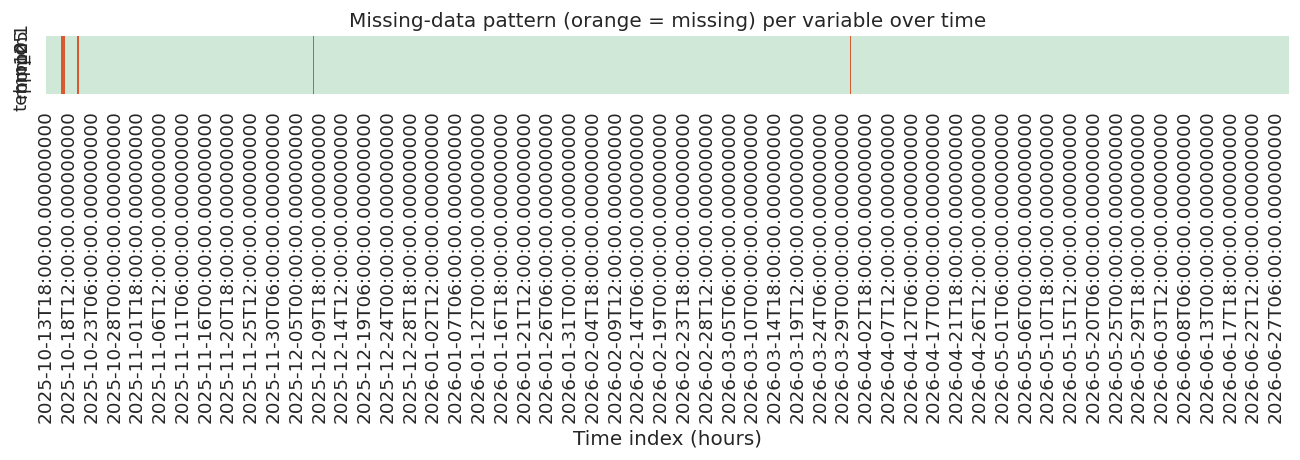

In [ ]:
# Visualize the missing-data pattern (helps determine the imputation strategy)
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(df[["pm1", "pm25", "pm10", "temp_c", "rh"]].isna().T,
            cbar=False, cmap=["#cfe8d8", "#d85a30"], ax=ax)
ax.set_title("Missing-data pattern (orange = missing) per variable over time")
ax.set_xlabel("Time index (hours)")
plt.tight_layout()
savefig(fig, "01_missing_data_pattern.png")
plt.show()


In [ ]:
# Imputation: linear interpolation for short gaps (<=3 hours); longer gaps are left as NaN
# and dropped during modeling.
num_cols = ["pm1", "pm25", "pm10", "temp_c", "rh", "pressure", "aqi_us"]
num_cols = [c for c in num_cols if c in df.columns]

df[num_cols] = df[num_cols].interpolate(method="linear", limit=3, limit_direction="both")

# Remove physically implausible extreme outliers (negative PM values)
for c in ["pm1", "pm25", "pm10"]:
    df.loc[df[c] < 0, c] = np.nan

print("Percentage of missing values after limited interpolation:")
print((df[num_cols].isna().mean() * 100).round(2))


Percentage of missing values after limited interpolation:
pm1         0.31
pm25        0.31
pm10        0.31
temp_c      0.31
rh          0.31
pressure    0.31
aqi_us      0.31
dtype: float64


## 4. Exploratory Data Analysis (EDA)

Saved: outputs/02_timeseries_pm_all.png


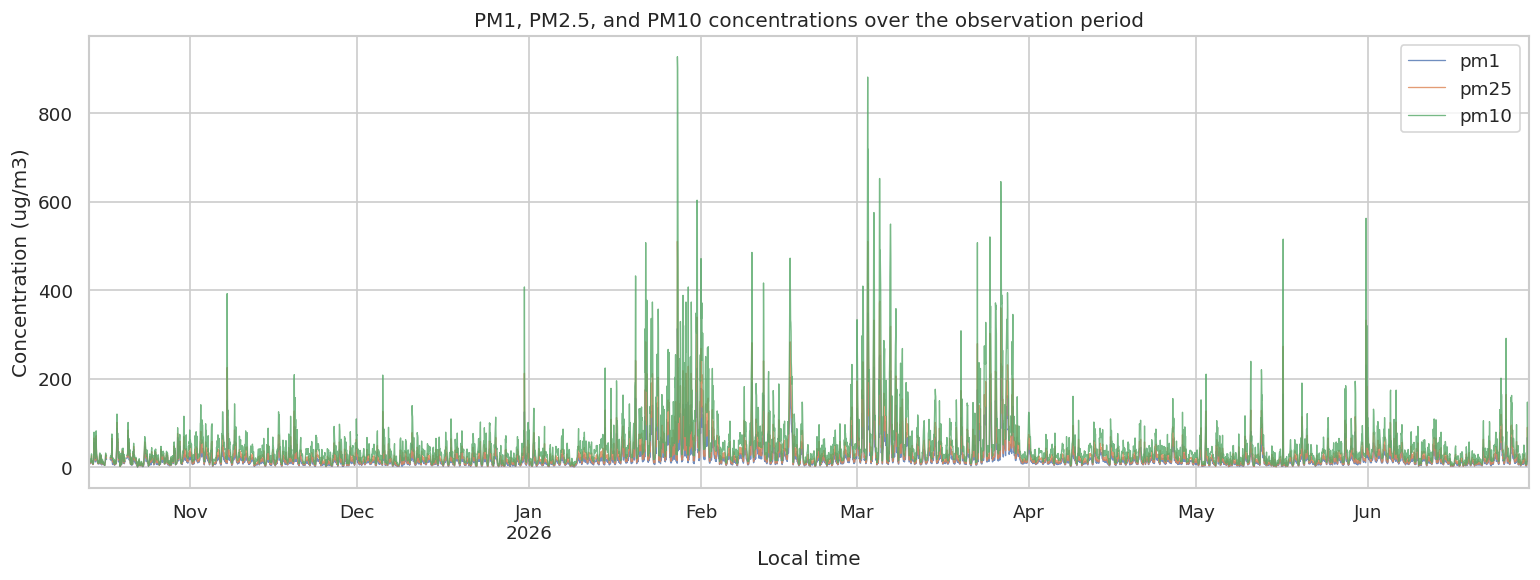

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
df[["pm1", "pm25", "pm10"]].plot(ax=ax, alpha=0.8, linewidth=0.8)
ax.set_title("PM1, PM2.5, and PM10 concentrations over the observation period")
ax.set_ylabel("Concentration (ug/m3)")
ax.set_xlabel("Local time")
plt.tight_layout()
savefig(fig, "02_timeseries_pm_all.png")
plt.show()


Saved: outputs/03_distribution_pm.png


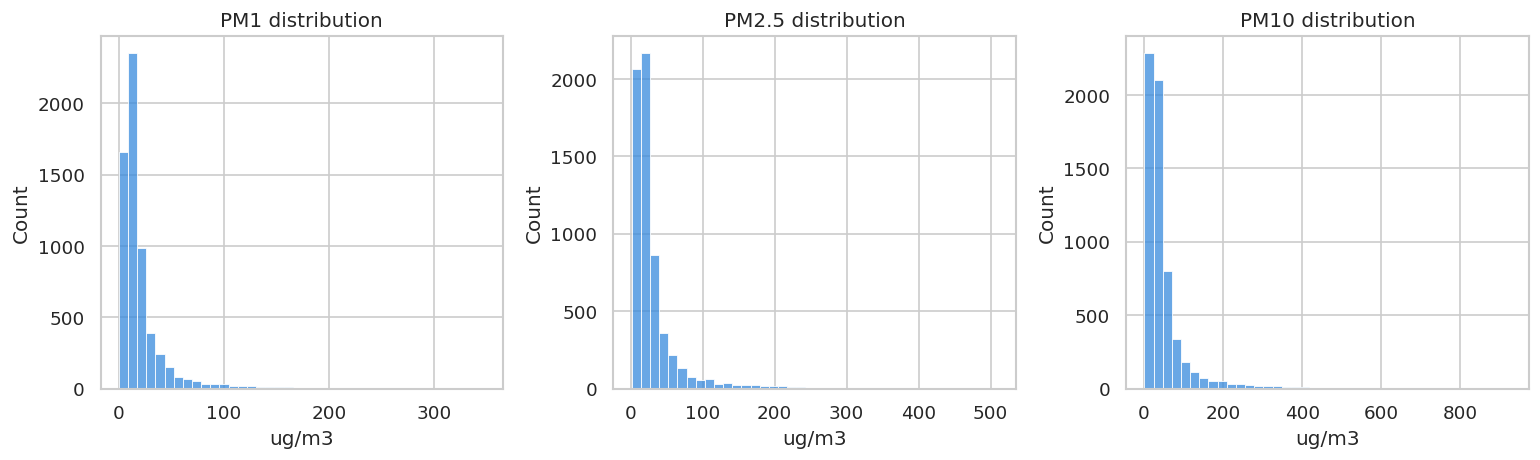

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, label in zip(axes, ["pm1", "pm25", "pm10"], ["PM1", "PM2.5", "PM10"]):
    sns.histplot(df[col].dropna(), bins=40, ax=ax, color="#378ADD")
    ax.set_title(f"{label} distribution")
    ax.set_xlabel("ug/m3")
plt.tight_layout()
savefig(fig, "03_distribution_pm.png")
plt.show()


Saved: outputs/04_diurnal_pattern.png


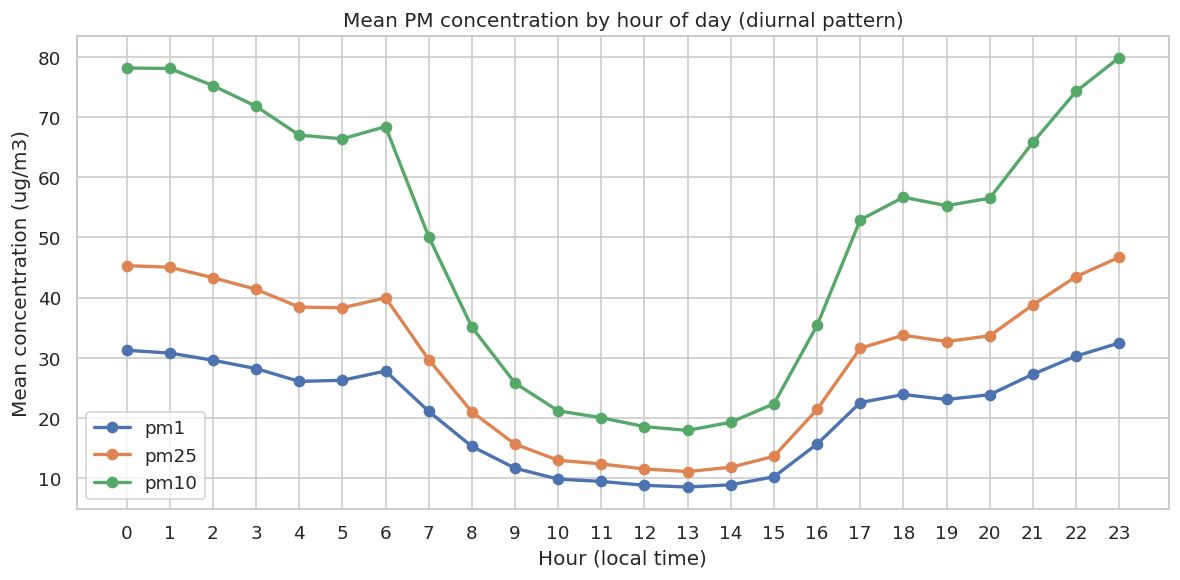

In [ ]:
# Diurnal pattern (hourly mean) -- important for the "why are they different" argument
df_hourly_pattern = df.copy()
df_hourly_pattern["hour"] = df_hourly_pattern.index.hour

hourly_mean = df_hourly_pattern.groupby("hour")[["pm1", "pm25", "pm10"]].mean()

fig, ax = plt.subplots(figsize=(10, 5))
hourly_mean.plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Mean PM concentration by hour of day (diurnal pattern)")
ax.set_xlabel("Hour (local time)")
ax.set_ylabel("Mean concentration (ug/m3)")
ax.set_xticks(range(0, 24))
plt.tight_layout()
savefig(fig, "04_diurnal_pattern.png")
plt.show()


Saved: outputs/05_weekly_pattern.png


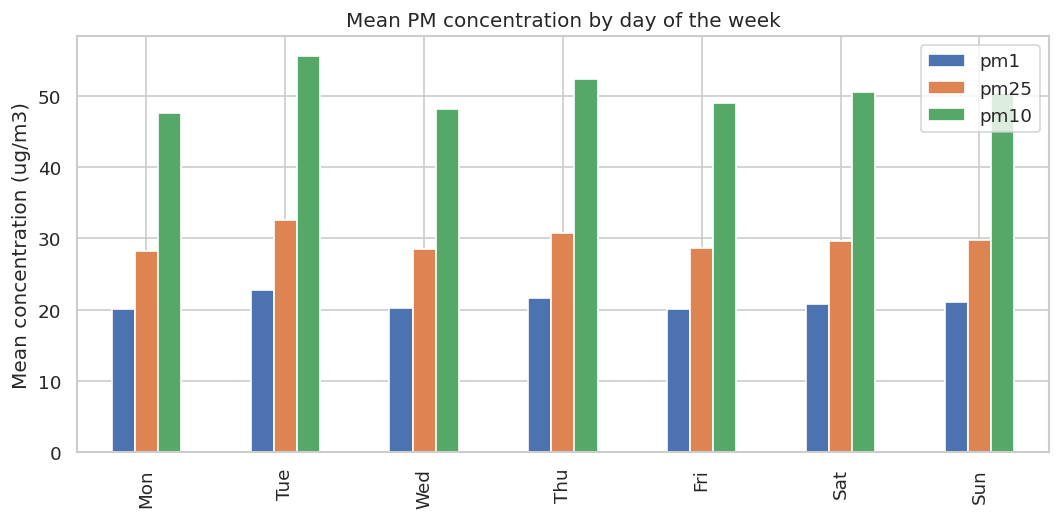

In [ ]:
# Weekly pattern: weekday vs weekend
df_hourly_pattern["dow"] = df_hourly_pattern.index.dayofweek  # 0=Monday
dow_mean = df_hourly_pattern.groupby("dow")[["pm1", "pm25", "pm10"]].mean()
dow_mean.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(9, 4.5))
dow_mean.plot(kind="bar", ax=ax)
ax.set_title("Mean PM concentration by day of the week")
ax.set_ylabel("Mean concentration (ug/m3)")
plt.tight_layout()
savefig(fig, "05_weekly_pattern.png")
plt.show()


Saved: outputs/06_correlation_heatmap.png


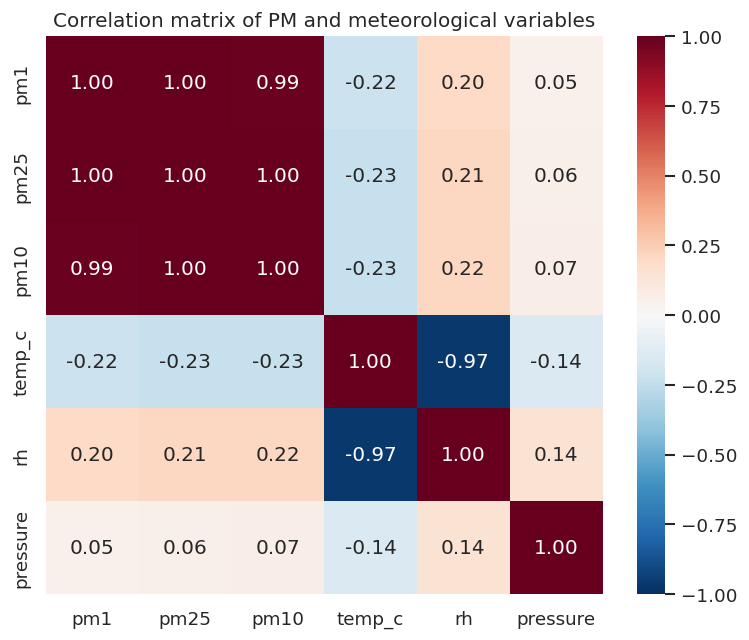

In [ ]:
# Correlation among variables
fig, ax = plt.subplots(figsize=(6.5, 5.5))
corr = df[["pm1", "pm25", "pm10", "temp_c", "rh", "pressure"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, vmin=-1, vmax=1)
ax.set_title("Correlation matrix of PM and meteorological variables")
plt.tight_layout()
savefig(fig, "06_correlation_heatmap.png")
plt.show()


## 5. Feature engineering

In [ ]:
data = df.copy()
data["hour"] = data.index.hour
data["dow"] = data.index.dayofweek
data["month"] = data.index.month
data["is_weekend"] = (data["dow"] >= 5).astype(int)

# Cyclical encoding so the model captures continuity (23 -> 0)
data["hour_sin"] = np.sin(2 * np.pi * data["hour"] / 24)
data["hour_cos"] = np.cos(2 * np.pi * data["hour"] / 24)
data["month_sin"] = np.sin(2 * np.pi * data["month"] / 12)
data["month_cos"] = np.cos(2 * np.pi * data["month"] / 12)

# Simplified season for West Kalimantan: dry season (May-Oct) vs wet season (Nov-Apr)
data["season_dry"] = data["month"].isin([5, 6, 7, 8, 9, 10]).astype(int)

feature_cols = ["hour_sin", "hour_cos", "month_sin", "month_cos",
                 "dow", "is_weekend", "season_dry", "temp_c", "rh"]
if "pressure" in data.columns and data["pressure"].notna().mean() > 0.5:
    feature_cols.append("pressure")

targets = ["pm1", "pm25", "pm10"]

model_df = data[feature_cols + targets].dropna()
print("Number of rows ready for modeling:", model_df.shape[0])
print("Features used:", feature_cols)
model_df.head()


Number of rows ready for modeling: 6203
Features used: ['hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dow', 'is_weekend', 'season_dry', 'temp_c', 'rh', 'pressure']


,hour_sin,hour_cos,month_sin,month_cos,dow,is_weekend,season_dry,temp_c,rh,pressure,pm1,pm25,pm10
datetime_local,,,,,,,,,,,,,
2025-10-13 18:00:00,-1.000000,-1.836970e-16,-0.866025,0.5,0,0,1,31.0,72.0,100886.0,19.0,22.0,26.0
2025-10-13 19:00:00,-0.965926,2.588190e-01,-0.866025,0.5,0,0,1,31.0,71.0,100921.0,15.0,17.0,20.0
2025-10-13 20:00:00,-0.866025,5.000000e-01,-0.866025,0.5,0,0,1,30.0,71.0,100948.0,15.0,17.0,20.0
2025-10-13 21:00:00,-0.707107,7.071068e-01,-0.866025,0.5,0,0,1,30.0,71.0,100962.0,13.0,16.0,19.0
2025-10-13 22:00:00,-0.500000,8.660254e-01,-0.866025,0.5,0,0,1,29.0,71.0,100961.0,13.0,15.0,19.0


## 6. Modeling: three separate models per particle size

Each target (PM1, PM2.5, PM10) is trained as a separate regression model so that feature attribution patterns (SHAP) can be fairly compared across particle sizes in the next step.

In [ ]:
# Time-based split (not a random split) to avoid data leakage
model_df_sorted = model_df.sort_index()
split_idx = int(len(model_df_sorted) * 0.8)

train_df = model_df_sorted.iloc[:split_idx]
test_df = model_df_sorted.iloc[split_idx:]

X_train, X_test = train_df[feature_cols], test_df[feature_cols]

print(f"Training data: {len(train_df)} hours ({train_df.index.min()} to {train_df.index.max()})")
print(f"Test data    : {len(test_df)} hours ({test_df.index.min()} to {test_df.index.max()})")


Training data: 4962 hours (2025-10-13 18:00:00 to 2026-05-09 06:00:00)
Test data    : 1241 hours (2026-05-09 07:00:00 to 2026-06-29 23:00:00)


In [ ]:
def get_models():
    return {
        "RandomForest": RandomForestRegressor(
            n_estimators=400, max_depth=None, min_samples_leaf=2,
            random_state=42, n_jobs=-1),
        "XGBoost": xgb.XGBRegressor(
            n_estimators=500, max_depth=6, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1),
        "LightGBM": lgb.LGBMRegressor(
            n_estimators=500, max_depth=-1, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1, verbosity=-1),
    }

def evaluate(y_true, y_pred):
    # RMSE is computed manually (np.sqrt) for compatibility across scikit-learn versions,
    # since the 'squared' parameter of mean_squared_error has been removed in recent versions.
    mse = mean_squared_error(y_true, y_pred)
    return {
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


In [ ]:
results = []
trained_models = {}   # trained_models[target][algo_name] = fitted model

for target in targets:
    y_train = train_df[target]
    y_test = test_df[target]
    trained_models[target] = {}

    for name, model in get_models().items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        metrics = evaluate(y_test, y_pred)
        metrics.update({"target": target, "model": name})
        results.append(metrics)
        trained_models[target][name] = model

results_df = pd.DataFrame(results)[["target", "model", "RMSE", "MAE", "R2"]]
results_df = results_df.sort_values(["target", "R2"], ascending=[True, False]).reset_index(drop=True)
results_df


,target,model,RMSE,MAE,R2
0,pm1,RandomForest,14.270557,7.718590,0.210681
1,pm1,LightGBM,15.002940,8.629430,0.127584
2,pm1,XGBoost,16.134892,9.308039,-0.009027
3,pm10,RandomForest,36.368470,18.392498,0.187662
4,pm10,LightGBM,38.436786,20.866537,0.092638
5,pm10,XGBoost,41.559955,23.017644,-0.060808
6,pm25,RandomForest,20.898342,10.925604,0.199717
7,pm25,LightGBM,22.145706,12.429317,0.101333
8,pm25,XGBoost,23.999322,13.629125,-0.055401


In [ ]:
# Select the best model per target based on the highest R2 on the test set
best_model_name = {}
best_model = {}

for target in targets:
    sub = results_df[results_df["target"] == target]
    best_row = sub.iloc[0]
    best_model_name[target] = best_row["model"]
    best_model[target] = trained_models[target][best_row["model"]]
    print(f"{target}: best model = {best_row['model']} "
          f"(R2={best_row['R2']:.3f}, RMSE={best_row['RMSE']:.2f}, MAE={best_row['MAE']:.2f})")


pm1: best model = RandomForest (R2=0.211, RMSE=14.27, MAE=7.72)
pm25: best model = RandomForest (R2=0.200, RMSE=20.90, MAE=10.93)
pm10: best model = RandomForest (R2=0.188, RMSE=36.37, MAE=18.39)


Saved: outputs/07_model_comparison_r2.png


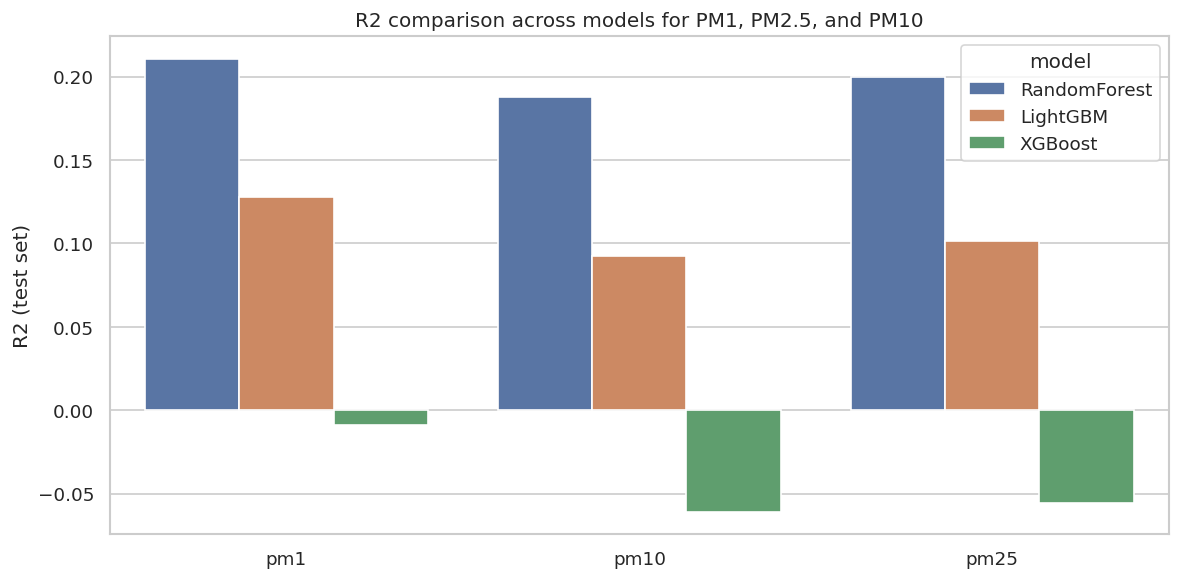

In [ ]:
# Visualize model performance comparison across targets
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=results_df, x="target", y="R2", hue="model", ax=ax)
ax.set_title("R2 comparison across models for PM1, PM2.5, and PM10")
ax.set_ylabel("R2 (test set)")
ax.set_xlabel("")
plt.tight_layout()
savefig(fig, "07_model_comparison_r2.png")
plt.show()


Saved: outputs/08_prediction_vs_actual.png


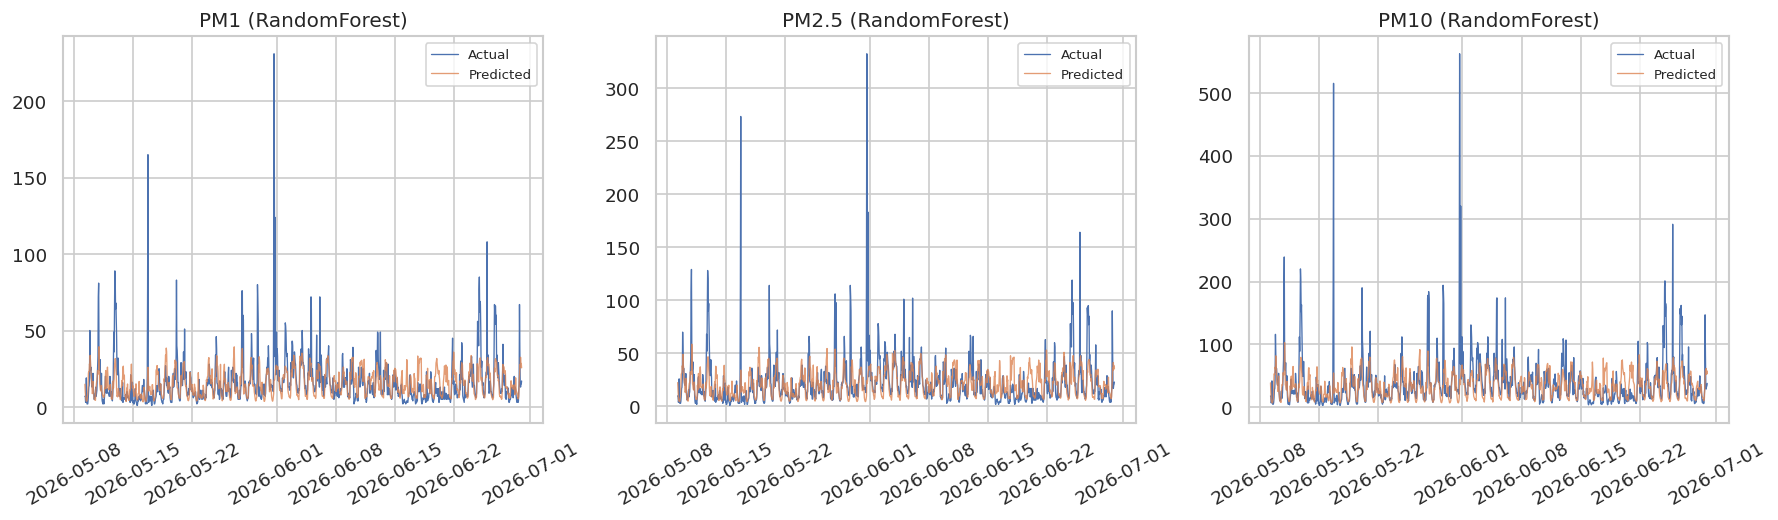

In [ ]:
# Predicted vs actual plot for the best model per target
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, target, label in zip(axes, targets, ["PM1", "PM2.5", "PM10"]):
    y_test = test_df[target]
    y_pred = best_model[target].predict(X_test)
    ax.plot(test_df.index, y_test, label="Actual", linewidth=0.8)
    ax.plot(test_df.index, y_pred, label="Predicted", linewidth=0.8, alpha=0.8)
    ax.set_title(f"{label} ({best_model_name[target]})")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=8)
plt.tight_layout()
savefig(fig, "08_prediction_vs_actual.png")
plt.show()


## 7. Interpretability analysis (SHAP)

This section is the core contribution of the study: comparing feature attribution patterns across the three particle sizes to explain *why* PM1 behaves differently from PM2.5/PM10.

In [ ]:
# Compute SHAP values for the best model per target
# Note: for RandomForest/XGBoost/LightGBM, TreeExplainer is the most efficient choice.
shap_values_dict = {}
explainer_dict = {}

X_test_sample = X_test.copy()  # use the full test set; reduce if too slow, e.g. X_test.sample(1000, random_state=42)

for target in targets:
    model = best_model[target]
    explainer = shap.TreeExplainer(model)
    sv = explainer.shap_values(X_test_sample)
    shap_values_dict[target] = sv
    explainer_dict[target] = explainer
    print(f"SHAP values computed for target: {target} ({best_model_name[target]})")


SHAP values computed for target: pm1 (RandomForest)
SHAP values computed for target: pm25 (RandomForest)
SHAP values computed for target: pm10 (RandomForest)


Saved: outputs/09_shap_summary_pm1.png


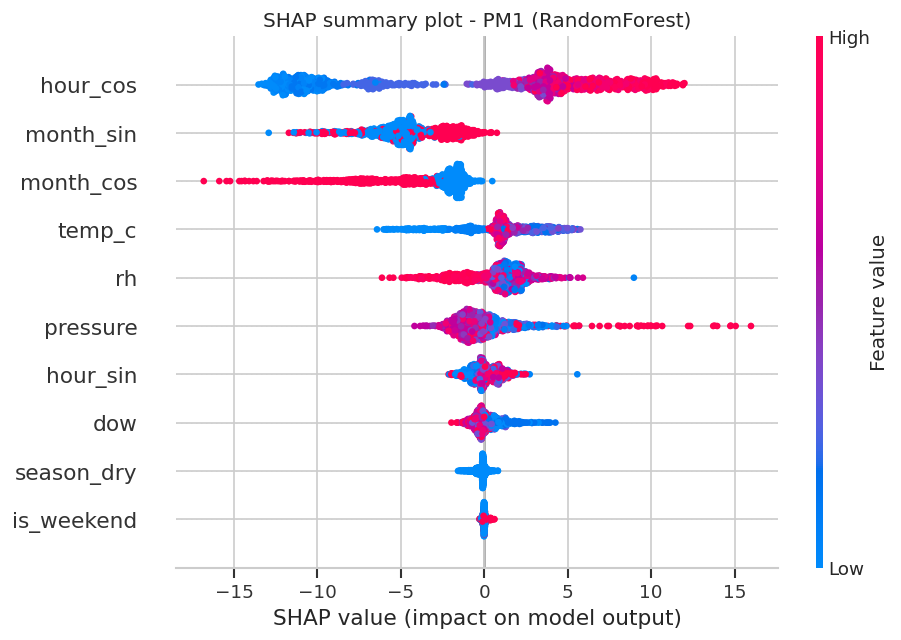

Saved: outputs/09_shap_summary_pm25.png


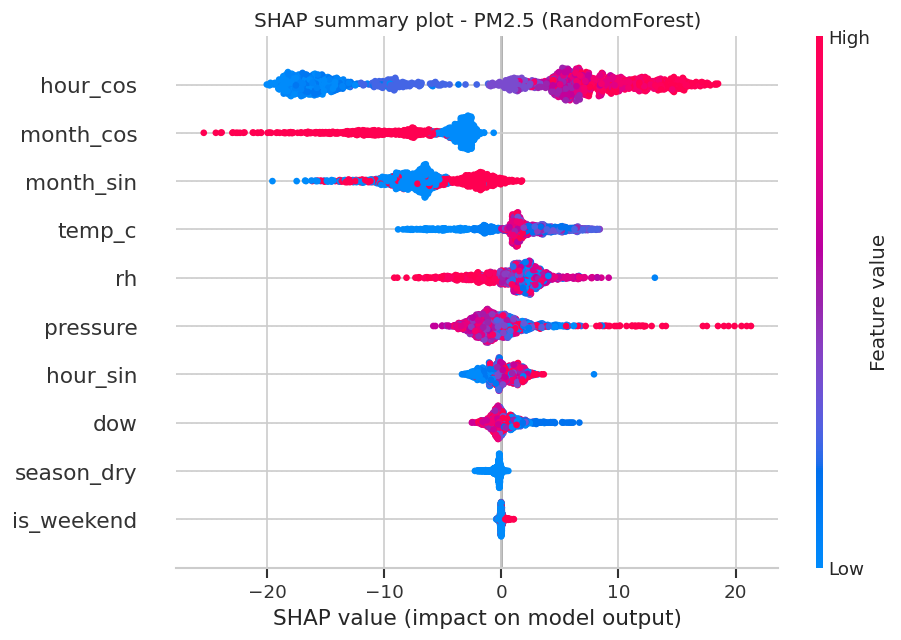

Saved: outputs/09_shap_summary_pm10.png


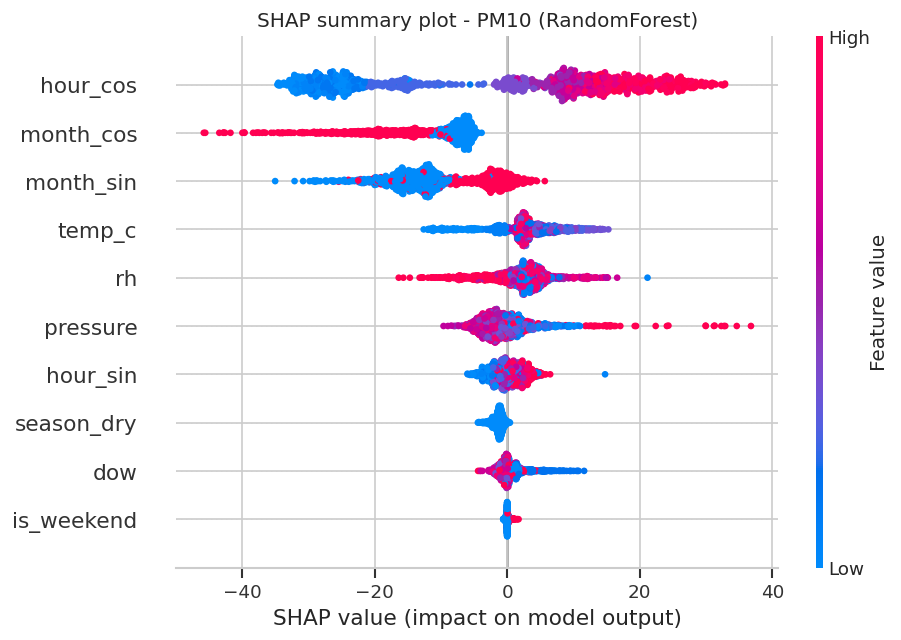

In [ ]:
# Summary plot (beeswarm) per target -- saved separately for use in the manuscript
for target, label in zip(targets, ["PM1", "PM2.5", "PM10"]):
    fig = plt.figure(figsize=(8, 5))
    shap.summary_plot(shap_values_dict[target], X_test_sample, show=False)
    plt.title(f"SHAP summary plot - {label} ({best_model_name[target]})")
    plt.tight_layout()
    savefig(plt.gcf(), f"09_shap_summary_{target}.png")
    plt.show()


In [ ]:
# Mean |SHAP value| per feature -- for quantitatively comparing feature ranking across the three targets
importance_table = pd.DataFrame(index=feature_cols)

for target in targets:
    mean_abs_shap = np.abs(shap_values_dict[target]).mean(axis=0)
    importance_table[target] = mean_abs_shap

importance_table = importance_table.round(3)
importance_table


,pm1,pm25,pm10
hour_sin,0.660,1.080,1.924
hour_cos,6.971,10.409,17.788
month_sin,4.449,6.072,10.427
month_cos,3.901,6.469,12.500
dow,0.567,0.822,1.239
is_weekend,0.068,0.097,0.162
season_dry,0.236,0.355,1.370
temp_c,2.009,2.753,4.373
rh,1.621,2.325,3.828
pressure,1.386,1.902,3.110


Saved: outputs/10_shap_importance_comparison.png


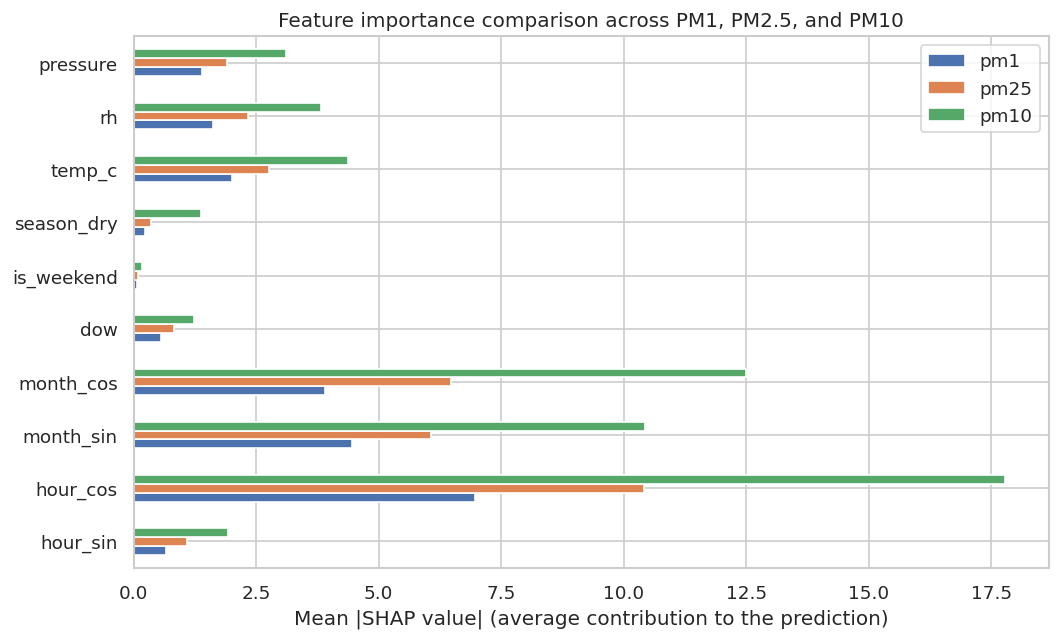

In [ ]:
# Visualize the comparison of feature ranking across PM1, PM2.5, and PM10 in a single chart
fig, ax = plt.subplots(figsize=(9, 5.5))
importance_table.plot(kind="barh", ax=ax)
ax.set_xlabel("Mean |SHAP value| (average contribution to the prediction)")
ax.set_title("Feature importance comparison across PM1, PM2.5, and PM10")
plt.tight_layout()
savefig(fig, "10_shap_importance_comparison.png")
plt.show()


Saved: outputs/11_shap_dependence_key_features.png


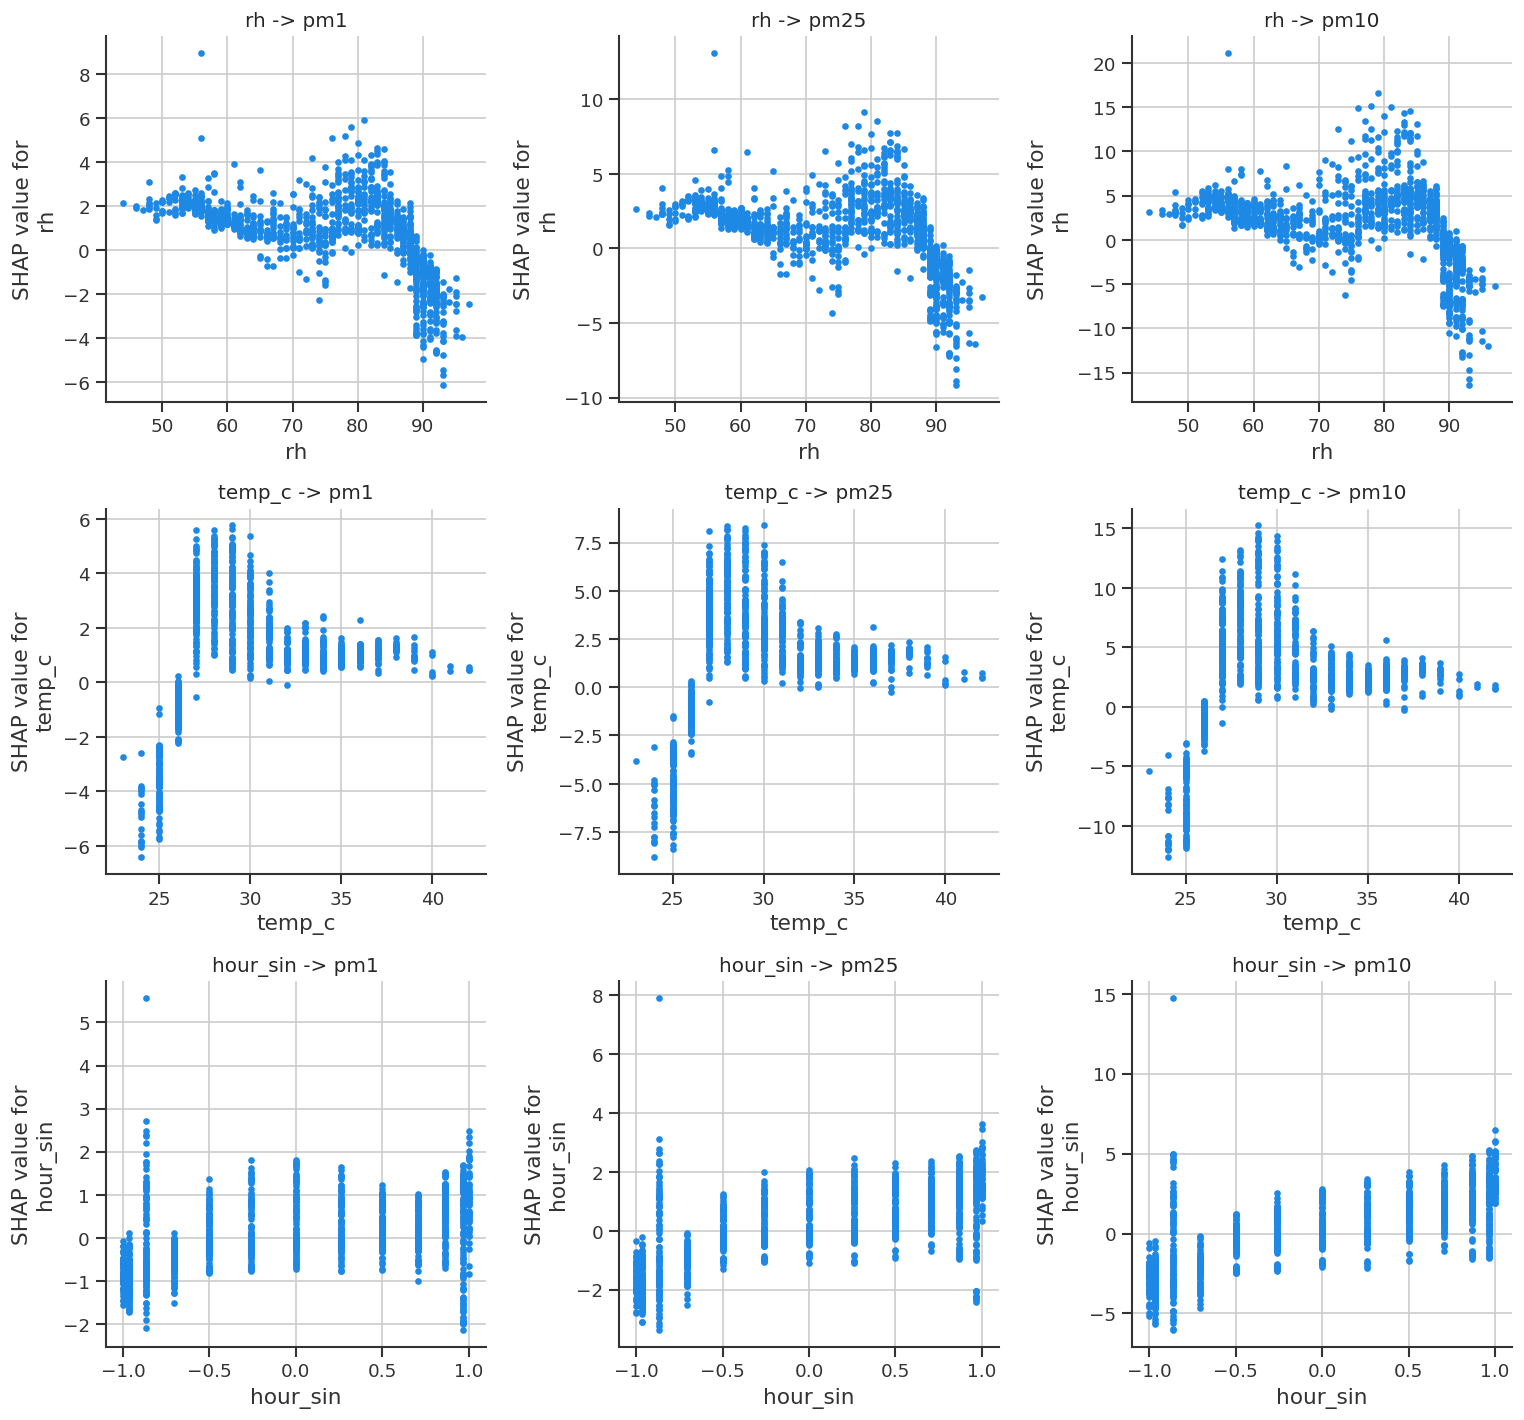

In [ ]:
# Simple partial dependence for key features (temperature and humidity) per target
key_features = [f for f in ["rh", "temp_c", "hour_sin"] if f in feature_cols]

fig, axes = plt.subplots(len(key_features), len(targets), figsize=(13, 4 * len(key_features)))
if len(key_features) == 1:
    axes = axes.reshape(1, -1)

for i, feat in enumerate(key_features):
    for j, target in enumerate(targets):
        shap.dependence_plot(feat, shap_values_dict[target], X_test_sample,
                              ax=axes[i, j], show=False, interaction_index=None)
        axes[i, j].set_title(f"{feat} -> {target}")

plt.tight_layout()
savefig(fig, "11_shap_dependence_key_features.png")
plt.show()


## 8. Results summary and domain interpretation

Use the cell below to record your narrative interpretation after reviewing the SHAP results above, for example:
- Which features are most dominant for PM10/PM2.5 (likely related to rush-hour traffic and road dust resuspension)?
- Which features are most dominant for PM1 (likely related to humidity/temperature, indicating secondary/hygroscopic processes characteristic of tropical riverine conditions)?
- Is this pattern consistent with the initial hypothesis stated in the abstract?

In [31]:
# Save the evaluation results and feature importance tables to CSV for the manuscript appendix
results_df.to_csv(os.path.join(OUTPUT_DIR, "model_evaluation_results.csv"), index=False)
importance_table.to_csv(os.path.join(OUTPUT_DIR, "shap_feature_importance_comparison.csv"))

print("All tables and figures have been saved to:", os.path.abspath(OUTPUT_DIR))
print("Please download the entire contents of this folder to your computer.")


All tables and figures have been saved to: /content/outputs
Please download the entire contents of this folder to your computer.


## Download all results as a zip file

In [32]:
from google.colab import files
import shutil

# Create a zip archive of the outputs directory
zip_filename = 'analysis_results.zip'
shutil.make_archive(zip_filename.replace('.zip', ''), 'zip', OUTPUT_DIR)

# Provide a link to download the zip file
files.download(zip_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>